In [11]:
from json.decoder import NaN

from app.background_tasks.tasks.lab import lab

In [24]:

# compare_strategy_mining takes a single `config` dict that overrides lab.DEFAULTS.
# First run: 5x the default budget.
lab.compare_strategy_mining.delay({"budget": lab.DEFAULTS["budget"] * 5, "arms" : [5]})

# Second run: default budget, but on the 1m timeframe.
# lab.compare_strategy_mining.delay({"timeframe": "1m"})

<AsyncResult: b9276c5b-2bbd-4f95-805d-7e8d6bf6f503>

In [ ]:
lab.compare_strategy_mining.delay({"budget": lab.DEFAULTS["budget"] * 5, "arms" : [4], "budget_multipliers" : {"arm4" : 0.8}})



In [15]:
import pandas as pd
from sqlalchemy import select

from app.data.database.models import MiningRun, BacktestResult, ArmResult
from app.data.database.session import db_session

In [ ]:
with db_session() as db:
    tests = db.execute(select(BacktestResult)).scalars().all()
    rows = [{
        "ticker" : r.dataset_name,
        "time" : r.test_time,
        "strategy" : r.strategy,
    } for r in tests]

tests_df = pd.DataFrame(rows)
tests_df

In [14]:
# Completed mining runs, one row per run. The per-arm comparison lives in run.summary["table"].


with db_session() as db:
    runs = db.execute(
        select(MiningRun).where(MiningRun.status == "done").order_by(MiningRun.created_at.desc())
    ).scalars().all()
    rows = [{
        "run_id": r.id,
        "created_at": r.created_at,
        "symbol": r.symbol,
        "timeframe": r.timeframe,
        "budget": r.budget,
        "arms": r.arms,
        "seeds": r.seeds,
        "model_id": r.model_id,
        "arm_results": len((r.summary or {}).get("table", [])),
    } for r in runs]

runs_df = pd.DataFrame(rows)
runs_df

,run_id,created_at,symbol,timeframe,budget,arms,seeds,model_id,arm_results
0,77,2026-11-24 01:28:20.483088+00:00,BTC/USDT,1h,10000,[4],[0],claude-haiku-5-5,1
1,75,2026-11-23 10:17:12.716125+00:00,BTC/USDT,1h,10000,[4],[0],claude-haiku-5-5,1
2,73,2026-11-22 19:46:45.893082+00:00,BTC/USDT,1h,10000,[4],[0],claude-haiku-5-5,1
3,36,2026-11-21 15:39:57.652697+00:00,BTC/USDT,1h,2000,"[1, 2, 3, 4, 5]",[0],claude-haiku-5-5,5
4,35,2026-11-21 12:29:19.805709+00:00,BTC/USDT,1h,2000,"[1, 2, 3, 4, 5]",[0],claude-haiku-5-5,5


In [37]:
import json

from app.data.database.models import ArmResult, BacktestResult

with db_session() as db:
    arm_results = db.execute(
        select(ArmResult)
        .where(ArmResult.rule != "NaN")
    ).scalars().all()
    rows = []
    for r in arm_results:
        bt = db.get(BacktestResult, r.backtest_result_id) if r.backtest_result_id else None
        res = json.loads(bt.results) if bt and bt.results else {}
        rows.append({
            "run_id": r.mining_run_id,
            "arm": r.arm,
            "seed": r.seed,
            "budget": r.mining_run.budget,
            "hold_out_sharpe": r.summary["hold-out sharpe"],
            "rule": r.rule,
        })

res_df = pd.DataFrame(rows)
res_df = res_df.sort_values(by=["hold_out_sharpe"])
res_df

,run_id,arm,seed,budget,hold_out_sharpe,rule
14,72,3,0,10000,-1.463885,"long_flat(and_(z_below(zscore(close, 6), 1.95)..."
12,72,1,0,10000,-1.359152,"long_flat(and_(z_above(vol_regime(20, 100), 0...."
0,35,1,0,2000,-1.049383,"long_flat(cross_up(sma(close, 20), sma(close, ..."
10,36,4,0,2000,-0.995167,"long_flat(and_(z_above(mom(close, 49), 1.05), ..."
15,73,4,0,10000,-0.849026,"long_flat(and_(cross_up(sma(close, 113), sma(c..."
9,36,1,0,2000,-0.744927,"long_flat(cross_up(sma(close, 20), sma(close, ..."
17,77,4,0,10000,-0.654850,"long_flat(and_(cross_up(close, bb_up(close, 10..."
13,72,2,0,10000,-0.604046,"long_flat(osc_below(stoch(480), 10.0), cross_u..."
7,35,3,0,2000,-0.585186,"long_flat(gt(close, lag(rmax(high, 190), 14)),..."
2,35,4,0,2000,-0.472739,"long_flat(and_(and_(gt(close, sma(close, 57)),..."


In [41]:
# Best finalist per (arm, budget): the row with the highest hold-out sharpe.
best_df = res_df.loc[
    res_df.groupby(["arm", "budget"])["hold_out_sharpe"].idxmax()
].reset_index(drop=True).sort_values(by=["hold_out_sharpe"])

best_df

,run_id,arm,seed,budget,hold_out_sharpe,rule
5,72,3,0,10000,-1.463885,"long_flat(and_(z_below(zscore(close, 6), 1.95)..."
1,72,1,0,10000,-1.359152,"long_flat(and_(z_above(vol_regime(20, 100), 0...."
0,36,1,0,2000,-0.744927,"long_flat(cross_up(sma(close, 20), sma(close, ..."
3,72,2,0,10000,-0.604046,"long_flat(osc_below(stoch(480), 10.0), cross_u..."
6,35,4,0,2000,-0.472739,"long_flat(and_(and_(gt(close, sma(close, 57)),..."
7,75,4,0,10000,-0.281987,"long_flat(and_(z_above(mom(close, 120), 2.0), ..."
4,36,3,0,2000,0.025279,"long_flat(and_(z_above(vol_regime(323, 237), -..."
2,36,2,0,2000,0.626831,"long_flat(z_below(vol_regime(18, 45), -1.0), g..."
8,35,5,0,2000,1.175696,"long_flat(cross_up(high, close), gt(rmax(rmin(..."


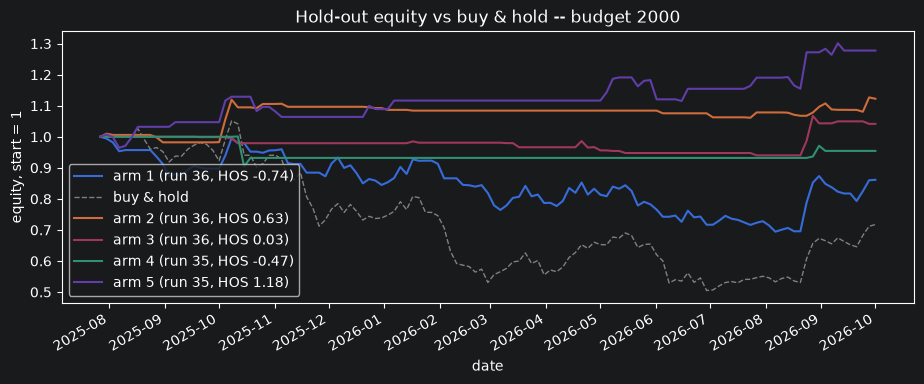

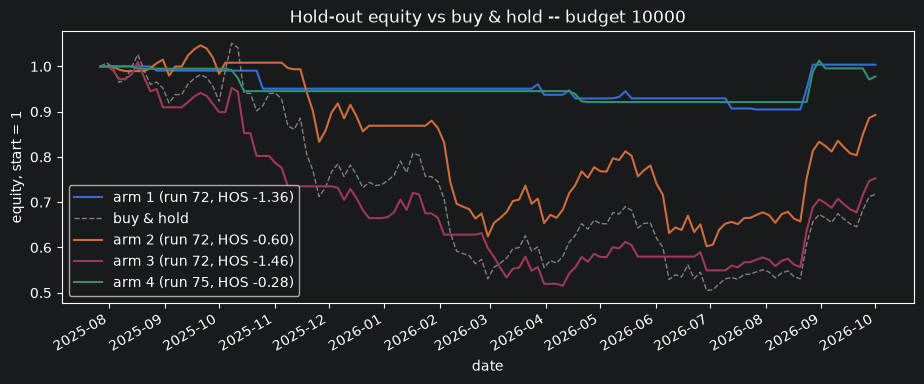

In [42]:
# Hold-out equity of each best finalist vs buy & hold, one graph per budget.
# The stored curves cover the full window; _downsample samples bars uniformly, so the hold-out
# is the last `holdout_fraction` of each curve (base = N_SEARCH), renormalised to start = 1 --
# the same slicing the reference notebook does with N_SEARCH.
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np


def _curve(js):
    return np.asarray(json.loads(js), dtype=float) if js else None


def plot_holdout(ax, budget):
    sub = best_df[best_df["budget"] == budget].sort_values("arm")
    bh_drawn = False
    for _, row in sub.iterrows():
        with db_session() as db:
            ar = db.execute(
                select(ArmResult).where(
                    ArmResult.mining_run_id == row["run_id"],
                    ArmResult.arm == row["arm"],
                    ArmResult.seed == row["seed"],
                )
            ).scalar_one_or_none()
            run = db.get(MiningRun, int(row["run_id"]))
            bt = db.get(BacktestResult, ar.backtest_result_id) if ar and ar.backtest_result_id else None
            if bt is None:
                continue
            equity, bh = _curve(bt.equity_curve), _curve(bt.buy_and_hold_curve)
            holdout_fraction, start, end = run.holdout_fraction, run.start_date, run.end_date

        base = int(len(equity) * (1 - holdout_fraction))
        dates = pd.date_range(start, end, periods=len(equity))[base:]
        ax.plot(dates, equity[base:] / equity[base],
                label=f"arm {row['arm']} (run {row['run_id']}, HOS {row['hold_out_sharpe']:.2f})")
        if not bh_drawn and bh is not None:
            b = int(len(bh) * (1 - holdout_fraction))
            ax.plot(pd.date_range(start, end, periods=len(bh))[b:], bh[b:] / bh[b],
                    color="grey", lw=1.0, ls="--", label="buy & hold")
            bh_drawn = True

    ax.set_title(f"Hold-out equity vs buy & hold -- budget {budget}")
    ax.set_xlabel("date")
    ax.set_ylabel("equity, start = 1")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.legend()


for budget in (2000, 10000):
    fig, ax = plt.subplots(figsize=(11, 4))
    plot_holdout(ax, budget)
    fig.autofmt_xdate()
    plt.show()